# P2 — Modèle de référence (baseline) en apprentissage automatique classique

**Question posée :** que peut-on faire *sans* deep learning, avec des descripteurs calculés à la main ?

Le sujet impose ce modèle de référence. Il sert à deux choses :
1. donner un point de comparaison au ResNet de P3 (« le CNN apporte X points de ROC-AUC ») ;
2. montrer **pourquoi** une approche simple ne suffit pas : elle s'appuie sur la couleur de l'hôpital plutôt que sur la forme des cellules, et chute sur un hôpital inconnu.

**Démarche :**

| Étape | Ce qu'on fait |
|---|---|
| 1 | Charger les patchs avec le découpage sans fuite de P1 |
| 2 | Transformer chaque image en une ligne de nombres (couleur + texture) |
| 3 | Entraîner une régression logistique et une forêt aléatoire sur `train_interne` |
| 4 | Mesurer sur `val_interne` (hôpitaux connus) puis `val_ood` (H1, inconnu) |
| 5 | Refaire l'expérience avec la couleur seule, puis la texture seule |
| 6 | Interpréter : sur quoi le modèle s'appuie-t-il ? |

**Règle d'or :** le jeu `test` (hôpital 2) n'est **jamais** chargé dans ce notebook. Il ne sert qu'une fois, à la toute fin du projet, avec le modèle final.

Pas besoin de GPU : Exécution → Modifier le type d'exécution → Processeur suffit.

## 1. Charger les données

On réutilise la fonction de P1. Elle lit le parquet sur ton Drive, vérifie qu'il contient bien les 39 000 patchs attendus, ajoute la colonne `split_equipe` et contrôle qu'aucune lame ni patiente n'est partagée entre deux jeux.

In [1]:
import os, sys, io, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive
drive.mount("/content/drive")

if not os.path.exists("depot"):
    !git clone --depth 1 https://github.com/kenzo-kouokam/detection-metastases-camelyon17.git depot
sys.path.insert(0, "depot/p1_data")
from charger_donnees import charger_donnees

DOSSIER_RESULTATS = "/content/drive/MyDrive/SPE1/resultats_P2"
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)
SEED = 42

Mounted at /content/drive
Cloning into 'depot'...
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 29 (delta 1), reused 19 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (29/29), 3.76 MiB | 14.77 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [2]:
df = charger_donnees()

# Règle d'or : on retire H2 tout de suite, il n'est jamais touché ici.
df = df[df.split_equipe != "test"].reset_index(drop=True)
assert 2 not in set(df.center), "L'hôpital 2 ne doit pas apparaître dans ce notebook."

print(len(df), "patchs utilisés (test H2 exclu)")
pd.crosstab([df.split_equipe, df.center], df.label, margins=True)

31000 patchs utilisés (test H2 exclu)


label                     0      1    All
split_equipe  center                     
train_interne 0        2365   3085   5450
              3        3528   3575   7103
              4        3072   3858   6930
val_interne   0        2135   1415   3550
              3         972    925   1897
              4        1428    642   2070
val_ood       1        2000   2000   4000
All                   15500  15500  31000

**À lire dans le tableau :** `train_interne` et `val_interne` viennent des hôpitaux 0, 3 et 4, mais de patientes différentes. `val_ood` vient uniquement de l'hôpital 1, que le modèle ne verra jamais à l'entraînement. `label` vaut 1 pour un patch tumoral, 0 sinon.

## 2. Transformer chaque image en nombres

Un modèle classique ne sait pas lire une image : il lui faut un tableau, une ligne par patch, une colonne par caractéristique. On calcule deux familles de caractéristiques.

**a) Couleur — histogrammes (96 colonnes)**
On compte combien de pixels tombent dans chaque tranche de valeur, pour chaque canal :
- RGB (rouge, vert, bleu) : 16 tranches × 3 canaux = 48 colonnes ;
- HSV (teinte, saturation, luminosité) : 16 tranches × 3 canaux = 48 colonnes. HSV sépare la *teinte* de la *clarté*, ce qui décrit mieux la coloration H&E (rose = éosine, violet = hématoxyline, qui colore les noyaux).

Les histogrammes sont normalisés (somme = 1) : ils décrivent des proportions, pas des nombres de pixels.

**b) Texture — GLCM (12 colonnes)**
La GLCM (*Gray-Level Co-occurrence Matrix*) regarde l'image en niveaux de gris et compte, pour chaque paire de pixels voisins, quelles intensités apparaissent côte à côte. On en tire des indicateurs :
- **contraste** : les voisins sont-ils très différents ? (bords nets, noyaux sombres sur fond clair) ;
- **dissimilarité** : version plus douce du contraste ;
- **homogénéité** : la zone est-elle uniforme ? ;
- **énergie** : la texture est-elle répétitive, ordonnée ? ;
- **corrélation** : les intensités voisines évoluent-elles ensemble ? ;
- **ASM** : variante de l'énergie.

Chaque indicateur est calculé à deux distances (1 et 3 pixels) et moyenné sur 4 directions (0°, 45°, 90°, 135°) pour ne pas dépendre de l'orientation. Soit 6 × 2 = 12 colonnes.

**Pourquoi c'est intéressant :** les cellules tumorales ont des noyaux plus gros, plus sombres et plus serrés. La texture devrait capter un peu de cela **sans dépendre de la couleur de l'hôpital**. C'est une approximation grossière de la cytologie, que le CNN apprendra beaucoup mieux.

In [3]:
from skimage.color import rgb2hsv
from skimage.feature import graycomatrix, graycoprops

N_BINS = 16
NIVEAUX_GRIS = 32                 # on réduit 256 niveaux à 32 : GLCM plus stable et plus rapide
DISTANCES = [1, 3]
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPRIETES = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

COLS_COULEUR = ([f"rgb_{c}_{i}" for c in "RGB" for i in range(N_BINS)]
                + [f"hsv_{c}_{i}" for c in "HSV" for i in range(N_BINS)])
COLS_TEXTURE = [f"glcm_{p}_d{d}" for p in PROPRIETES for d in DISTANCES]


def decrire_patch(octets):
    # Renvoie les 108 caractéristiques d'un patch (96 couleur + 12 texture).
    rgb = np.asarray(Image.open(io.BytesIO(octets)).convert("RGB"))

    # Couleur : histogrammes RGB puis HSV, chacun normalisé
    h_rgb = [np.histogram(rgb[..., k], bins=N_BINS, range=(0, 256))[0] for k in range(3)]
    hsv = rgb2hsv(rgb)
    h_hsv = [np.histogram(hsv[..., k], bins=N_BINS, range=(0, 1))[0] for k in range(3)]
    couleur = np.concatenate(h_rgb + h_hsv).astype(float) / (rgb.shape[0] * rgb.shape[1])

    # Texture : GLCM sur l'image en niveaux de gris, réduite à 32 niveaux
    gris = (0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2])
    gris = (gris / 256 * NIVEAUX_GRIS).astype(np.uint8)
    glcm = graycomatrix(gris, DISTANCES, ANGLES, levels=NIVEAUX_GRIS, symmetric=True, normed=True)
    texture = np.concatenate([graycoprops(glcm, p).mean(axis=1) for p in PROPRIETES])  # moyenne sur les angles

    return np.concatenate([couleur, texture])


# Test sur un patch avant de tout lancer
v = decrire_patch(df.image.iloc[0])
print(len(v), "caractéristiques :", len(COLS_COULEUR), "couleur +", len(COLS_TEXTURE), "texture")

108 caractéristiques : 96 couleur + 12 texture


On calcule ces caractéristiques pour les 31 000 patchs (environ 2 à 4 minutes). Le résultat est enregistré sur ton Drive : si tu relances le notebook, il est relu directement au lieu d'être recalculé.

In [4]:
CACHE = f"{DOSSIER_RESULTATS}/caracteristiques_baseline.parquet"

if os.path.exists(CACHE):
    feats = pd.read_parquet(CACHE)
    print("Caractéristiques relues depuis le Drive.")
else:
    t0 = time.time()
    X_all = np.stack([decrire_patch(b) for b in df.image])
    feats = pd.DataFrame(X_all, columns=COLS_COULEUR + COLS_TEXTURE)
    feats.insert(0, "image_id", df.image_id.values)
    feats.to_parquet(CACHE, index=False)
    print(f"Calculé en {time.time() - t0:.0f} s et enregistré sur le Drive.")

data = df[["image_id", "center", "slide", "label", "split_equipe"]].merge(feats, on="image_id", validate="one_to_one")
train = data[data.split_equipe == "train_interne"]
val = data[data.split_equipe == "val_interne"]
ood = data[data.split_equipe == "val_ood"]
print(len(train), "train |", len(val), "val_interne |", len(ood), "val_ood (H1)")

Caractéristiques relues depuis le Drive.
19483 train | 7517 val_interne | 4000 val_ood (H1)


### Coup d'œil : ces caractéristiques séparent-elles les classes ? et les hôpitaux ?

Si une caractéristique varie davantage d'un **hôpital** à l'autre que d'une **classe** à l'autre, le modèle risque de s'appuyer sur l'hôpital. On compare deux exemples : la teinte moyenne (couleur) et le contraste (texture).

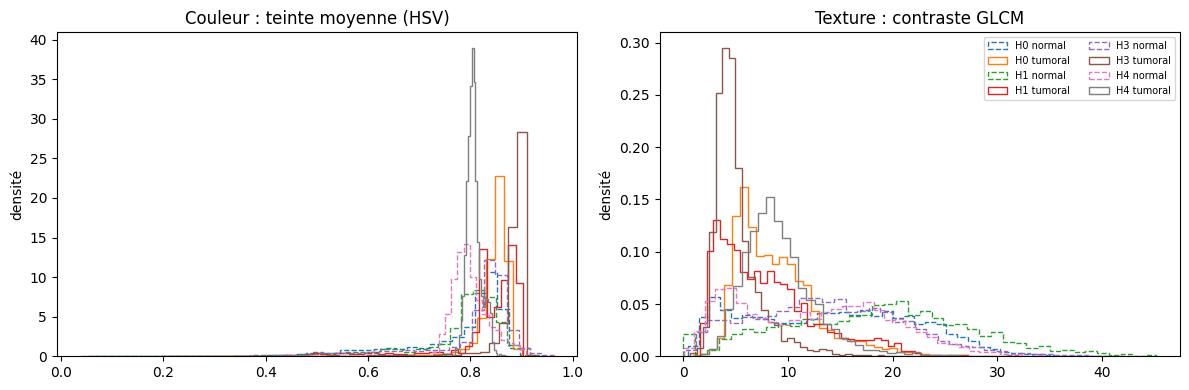

In [5]:
teinte_moy = (data[[f"hsv_H_{i}" for i in range(N_BINS)]].values * (np.arange(N_BINS) + 0.5) / N_BINS).sum(axis=1)
apercu = data.assign(teinte_moyenne=teinte_moy)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titre in [(axes[0], "teinte_moyenne", "Couleur : teinte moyenne (HSV)"),
                       (axes[1], "glcm_contrast_d1", "Texture : contraste GLCM")]:
    for (c, l), g in apercu.groupby(["center", "label"]):
        ax.hist(g[col], bins=40, histtype="step", density=True,
                linestyle="-" if l else "--", label=f"H{c} {'tumoral' if l else 'normal'}")
    ax.set_title(titre); ax.set_ylabel("densité")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{DOSSIER_RESULTATS}/distributions_caracteristiques.png", dpi=150); plt.show()

**Comment lire :** trait plein = tumoral, pointillé = normal, une couleur par hôpital. Si les courbes se regroupent par hôpital plutôt que par classe, la caractéristique « trahit » l'hôpital. À commenter dans le rapport avec ce que tu observes.

## 3. Les deux modèles

**Normalisation (StandardScaler).** Les colonnes n'ont pas la même échelle (un histogramme vaut entre 0 et 1, un contraste peut valoir 50). On ramène chaque colonne à une moyenne 0 et un écart-type 1. Point important : le *scaler* est ajusté **uniquement sur `train_interne`**, puis appliqué tel quel aux autres jeux. L'ajuster sur la validation serait une fuite d'information. Le `Pipeline` de scikit-learn garantit cela automatiquement.

**Régression logistique pénalisée (référence imposée).** Elle calcule une somme pondérée des caractéristiques et la transforme en probabilité d'être tumoral. La pénalité L2 empêche les poids de devenir énormes, ce qui limite le surapprentissage avec 108 colonnes. Elle est simple, rapide et interprétable : chaque poids dit si une caractéristique pousse vers « tumoral » ou « normal ».

**Forêt aléatoire (Random Forest).** Plusieurs centaines d'arbres de décision, chacun entraîné sur une partie des données et des colonnes, qui votent. Elle capte des interactions non linéaires (« si la teinte est X *et* le contraste est Y… ») que la régression logistique ne voit pas. Elle n'a pas besoin du scaler, mais il ne la gêne pas. On limite la profondeur des arbres pour éviter qu'elle n'apprenne les lames par cœur.

**Pourquoi les classes ne sont pas repondérées :** `train_interne` est presque équilibré (54 % de tumoral), donc `class_weight` ne changerait presque rien. Le déséquilibre réel (en clinique, la très grande majorité des patchs sont normaux) est traité plus loin par le choix du seuil.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, confusion_matrix, roc_curve


def creer_modele(nom):
    if nom == "Régression logistique":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))  # pénalité L2 par défaut
    return make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=SEED))


def mesurer(y, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"ROC-AUC": roc_auc_score(y, proba), "Rappel": recall_score(y, pred),
            "Précision": precision_score(y, pred, zero_division=0), "F1": f1_score(y, pred),
            "Faux négatifs": fn, "Faux positifs": fp}

**Les métriques, en clair :**
- **ROC-AUC** : capacité à classer un patch tumoral au-dessus d'un patch normal, quel que soit le seuil. 0,5 = hasard, 1 = parfait.
- **Rappel (sensibilité)** : parmi les vrais patchs tumoraux, combien sont détectés. **C'est la métrique prioritaire** : un patch tumoral manqué est un faux négatif, donc potentiellement une métastase non vue.
- **Précision** : parmi les patchs déclarés tumoraux, combien le sont vraiment. Une précision faible signifie de fausses alertes, que le pathologiste doit vérifier.
- **F1** : compromis entre les deux.

## 4. L'expérience principale : quelles caractéristiques, quel modèle ?

On entraîne les deux modèles sur trois jeux de caractéristiques :
- **Couleur seule** (histogrammes) ;
- **Texture seule** (GLCM, calculée en niveaux de gris, donc peu sensible à la teinte) ;
- **Tout** (couleur + texture).

Puis on mesure sur `val_interne` (hôpitaux connus) et `val_ood` (H1, inconnu). L'écart entre les deux colonnes mesure la **perte due au changement d'hôpital** (domain shift).

In [7]:
JEUX = {"Couleur seule": COLS_COULEUR, "Texture seule": COLS_TEXTURE, "Couleur + texture": COLS_COULEUR + COLS_TEXTURE}
MODELES = ["Régression logistique", "Random Forest"]

lignes, modeles_entraines, probas = [], {}, {}
for nom_jeu, cols in JEUX.items():
    for nom_mod in MODELES:
        m = creer_modele(nom_mod).fit(train[cols], train.label)
        modeles_entraines[(nom_jeu, nom_mod)] = m
        for nom_eval, d in [("val_interne", val), ("val_ood (H1)", ood)]:
            p = m.predict_proba(d[cols])[:, 1]
            probas[(nom_jeu, nom_mod, nom_eval)] = p
            lignes.append({"Caractéristiques": nom_jeu, "Modèle": nom_mod, "Jeu": nom_eval, **mesurer(d.label, p)})

resultats = pd.DataFrame(lignes)
tableau = resultats.pivot_table(index=["Caractéristiques", "Modèle"], columns="Jeu", values=["ROC-AUC", "Rappel"]).round(3)
tableau[("ROC-AUC", "chute H1")] = (tableau[("ROC-AUC", "val_ood (H1)")] - tableau[("ROC-AUC", "val_interne")]).round(3)
resultats.to_csv(f"{DOSSIER_RESULTATS}/resultats_baseline_seuil05.csv", index=False)
tableau

ROC-AUC                   Rappel  \
Jeu                                     val_interne val_ood (H1) val_interne   
Caractéristiques  Modèle                                                       
Couleur + texture Random Forest               0.904        0.860       0.532   
                  Régression logistique       0.864        0.729       0.595   
Couleur seule     Random Forest               0.874        0.835       0.506   
                  Régression logistique       0.837        0.708       0.561   
Texture seule     Random Forest               0.911        0.898       0.752   
                  Régression logistique       0.900        0.881       0.846   

                                                      ROC-AUC  
Jeu                                     val_ood (H1) chute H1  
Caractéristiques  Modèle                                       
Couleur + texture Random Forest                0.594   -0.044  
                  Régression logistique        0.602   -0.135  
Couleur seule     Random Forest                0.588   -0.039  
                  Régression logistique        0.624   -0.129  
Texture seule     Random Forest                0.534   -0.013  
                  Régression logistique        0.682   -0.019

**Ce qu'on s'attend à voir (à confirmer avec tes chiffres) :**
- *Couleur seule* : correcte sur les hôpitaux connus, mais nette chute sur H1, car le modèle a appris des teintes propres à H0, H3 et H4.
- *Texture seule* : moins bonne au départ, mais plus stable entre hôpitaux, car elle dépend moins de la coloration.
- *Couleur + texture* : souvent la meilleure sur `val_interne`, avec la même fragilité sur H1 que la couleur.

La **chute H1** (dernière colonne) est l'argument central à présenter : elle montre que la baseline apprend en partie la signature de l'hôpital, et justifie le passage au CNN avec normalisation de couleur.

## 5. Courbes ROC

Une courbe ROC montre tous les compromis possibles entre rappel (axe vertical) et fausses alertes (axe horizontal) quand on fait varier le seuil. Plus la courbe monte vite vers le coin en haut à gauche, meilleur est le modèle. Trait plein = hôpitaux connus, pointillé = H1.

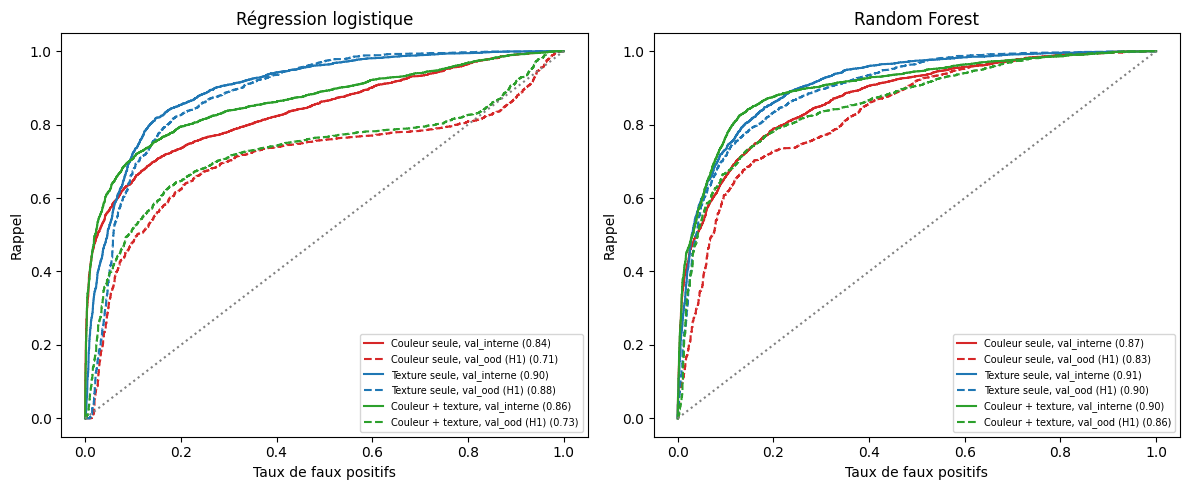

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nom_mod in zip(axes, MODELES):
    for nom_jeu, couleur in zip(JEUX, ["tab:red", "tab:blue", "tab:green"]):
        for nom_eval, d, style in [("val_interne", val, "-"), ("val_ood (H1)", ood, "--")]:
            fpr, tpr, _ = roc_curve(d.label, probas[(nom_jeu, nom_mod, nom_eval)])
            auc = roc_auc_score(d.label, probas[(nom_jeu, nom_mod, nom_eval)])
            ax.plot(fpr, tpr, style, color=couleur, label=f"{nom_jeu}, {nom_eval} ({auc:.2f})")
    ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.set_title(nom_mod); ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Rappel")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{DOSSIER_RESULTATS}/courbes_roc.png", dpi=150); plt.show()

## 6. Résultats hôpital par hôpital

Une moyenne peut cacher un hôpital où le modèle s'effondre. On détaille donc la ROC-AUC et le rappel pour chaque hôpital (H0, H3, H4 dans `val_interne`, H1 dans `val_ood`), avec le modèle complet (couleur + texture).

In [9]:
lignes = []
for nom_mod in MODELES:
    m = modeles_entraines[("Couleur + texture", nom_mod)]
    for c, d in pd.concat([val, ood]).groupby("center"):
        p = m.predict_proba(d[COLS_COULEUR + COLS_TEXTURE])[:, 1]
        lignes.append({"Modèle": nom_mod, "Hôpital": f"H{c}", "Patchs": len(d), **mesurer(d.label, p)})
par_hopital = pd.DataFrame(lignes).round(3)
par_hopital.to_csv(f"{DOSSIER_RESULTATS}/resultats_par_hopital.csv", index=False)
par_hopital

,Modèle,Hôpital,Patchs,ROC-AUC,Rappel,Précision,F1,Faux négatifs,Faux positifs
0,Régression logistique,H0,3550,0.796,0.510,0.900,0.651,693,80
1,Régression logistique,H1,4000,0.729,0.602,0.792,0.684,797,315
2,Régression logistique,H3,1897,0.977,0.883,0.963,0.922,108,31
3,Régression logistique,H4,2070,0.822,0.364,0.757,0.492,408,75
4,Random Forest,H0,3550,0.928,0.524,0.934,0.671,674,52
5,Random Forest,H1,4000,0.860,0.594,0.898,0.715,813,135
6,Random Forest,H3,1897,0.961,0.869,0.962,0.913,121,32
7,Random Forest,H4,2070,0.775,0.065,0.323,0.109,600,88


## 7. Choisir le seuil en fonction du coût des erreurs

Par défaut, un patch est déclaré tumoral si sa probabilité dépasse 0,5. Mais un faux négatif coûte bien plus cher qu'un faux positif. On abaisse donc le seuil pour atteindre un **rappel cible de 90 %**, en acceptant plus de fausses alertes.

Le seuil est choisi sur `val_ood` (H1), comme le prévoit le sujet (« H1 sert aux réglages »). On regarde ensuite ce que ce seuil donne sur `val_interne`.

C'est aussi un point à discuter : le seuil qui marche dans un hôpital n'est pas forcément le bon dans un autre.

On compare la **texture seule** (le meilleur modèle de la section 4, retenu comme baseline officielle) et **couleur + texture**, pour voir si retirer la couleur réduit aussi le coût en fausses alertes.

In [10]:
RAPPEL_CIBLE = 0.90

def seuil_pour_rappel(y, proba, cible):
    # Plus grand seuil qui atteint le rappel cible (donc le moins de fausses alertes possible).
    fpr, tpr, seuils = roc_curve(y, proba)
    ok = np.flatnonzero(tpr >= cible)
    return float(min(seuils[ok[0]], 1.0))

lignes = []
for nom_jeu in ["Texture seule", "Couleur + texture"]:
    for nom_mod in MODELES:
        cle = (nom_jeu, nom_mod)
        s = seuil_pour_rappel(ood.label, probas[cle + ("val_ood (H1)",)], RAPPEL_CIBLE)
        for nom_eval, d in [("val_ood (H1)", ood), ("val_interne", val)]:
            lignes.append({"Caractéristiques": nom_jeu, "Modèle": nom_mod, "Seuil": round(s, 4), "Jeu": nom_eval,
                           **mesurer(d.label, probas[cle + (nom_eval,)], seuil=s)})
seuils = pd.DataFrame(lignes).round(3)
seuils.to_csv(f"{DOSSIER_RESULTATS}/resultats_seuil_rappel90.csv", index=False)
seuils

,Caractéristiques,Modèle,Seuil,Jeu,ROC-AUC,Rappel,Précision,F1,Faux négatifs,Faux positifs
0,Texture seule,Régression logistique,0.092,val_ood (H1),0.881,0.900,0.735,0.809,200,649
1,Texture seule,Régression logistique,0.092,val_interne,0.900,0.969,0.545,0.698,92,2412
2,Texture seule,Random Forest,0.104,val_ood (H1),0.898,0.900,0.743,0.814,200,621
3,Texture seule,Random Forest,0.104,val_interne,0.911,0.969,0.580,0.725,92,2097
4,Couleur + texture,Régression logistique,0.000,val_ood (H1),0.729,0.900,0.504,0.646,199,1773
5,Couleur + texture,Régression logistique,0.000,val_interne,0.864,0.997,0.405,0.576,9,4364
6,Couleur + texture,Random Forest,0.089,val_ood (H1),0.860,0.900,0.650,0.755,200,969
7,Couleur + texture,Random Forest,0.089,val_interne,0.904,0.930,0.598,0.728,210,1864


**À commenter :** combien de fausses alertes coûte ce rappel de 90 % ? Le rappel tient-il sur `val_interne` avec le seuil réglé sur H1 ?

**Attention à la précision :** nos jeux sont équilibrés (50 % de patchs tumoraux). Dans une vraie lame, les patchs tumoraux sont très minoritaires (souvent moins de 5 %). À taux de faux positifs égal, la précision réelle serait donc **bien plus basse** que celle affichée ici. La cellule suivante l'estime.

In [11]:
# Précision attendue si seulement 2 % des patchs d'une lame étaient tumoraux
PREVALENCE_CLINIQUE = 0.02
for _, r in seuils.iterrows():
    d = ood if r.Jeu.startswith("val_ood") else val
    tpr = r.Rappel
    fpr = r["Faux positifs"] / (d.label == 0).sum()
    denom = tpr * PREVALENCE_CLINIQUE + fpr * (1 - PREVALENCE_CLINIQUE)
    prec = tpr * PREVALENCE_CLINIQUE / denom if denom else float("nan")
    print(f"{r.Caractéristiques:<18} {r.Modèle:<22} {r.Jeu:<14} précision mesurée {r.Précision:.2f} -> précision en clinique ≈ {prec:.2f}")

Texture seule      Régression logistique  val_ood (H1)   précision mesurée 0.73 -> précision en clinique ≈ 0.05
Texture seule      Régression logistique  val_interne    précision mesurée 0.55 -> précision en clinique ≈ 0.04
Texture seule      Random Forest          val_ood (H1)   précision mesurée 0.74 -> précision en clinique ≈ 0.06
Texture seule      Random Forest          val_interne    précision mesurée 0.58 -> précision en clinique ≈ 0.04
Couleur + texture  Régression logistique  val_ood (H1)   précision mesurée 0.50 -> précision en clinique ≈ 0.02
Couleur + texture  Régression logistique  val_interne    précision mesurée 0.41 -> précision en clinique ≈ 0.02
Couleur + texture  Random Forest          val_ood (H1)   précision mesurée 0.65 -> précision en clinique ≈ 0.04
Couleur + texture  Random Forest          val_interne    précision mesurée 0.60 -> précision en clinique ≈ 0.04


## 8. Sur quoi le modèle s'appuie-t-il ?

**Importance des caractéristiques (Random Forest).** Pour chaque colonne, on mesure à quel point elle contribue aux décisions des arbres. Si les 15 premières sont presque toutes des colonnes de couleur, le modèle décide surtout sur la teinte.

Part de l'importance portée par la couleur : 65%, par la texture : 35%


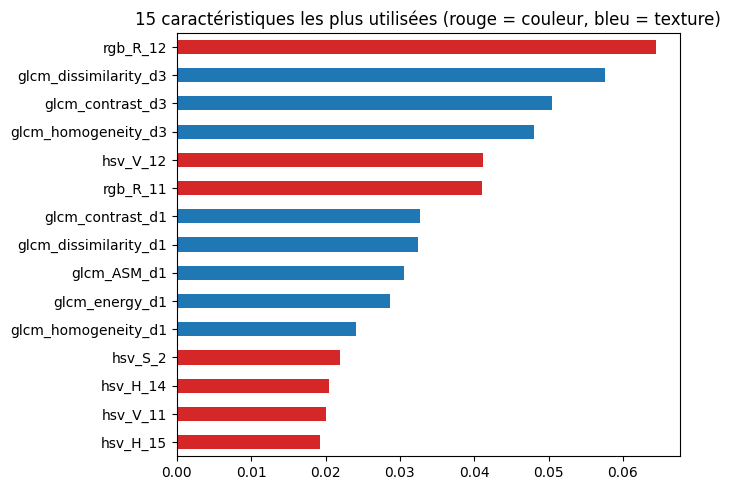

In [12]:
rf = modeles_entraines[("Couleur + texture", "Random Forest")][-1]
imp = pd.Series(rf.feature_importances_, index=COLS_COULEUR + COLS_TEXTURE).sort_values(ascending=False)
part_couleur = imp[COLS_COULEUR].sum()
print(f"Part de l'importance portée par la couleur : {part_couleur:.0%}, par la texture : {1 - part_couleur:.0%}")

top = imp.head(15)[::-1]
top.plot.barh(figsize=(7, 5), color=["tab:blue" if c.startswith("glcm") else "tab:red" for c in top.index])
plt.title("15 caractéristiques les plus utilisées (rouge = couleur, bleu = texture)")
plt.tight_layout(); plt.savefig(f"{DOSSIER_RESULTATS}/importance_caracteristiques.png", dpi=150); plt.show()

**Test décisif : le modèle reconnaît-il l'hôpital ?** On entraîne les mêmes caractéristiques à prédire non pas la tumeur, mais **l'hôpital d'origine** (H0, H3 ou H4). Si c'est très facile, cela prouve que ces caractéristiques contiennent la « signature » de l'hôpital, et donc que le modèle tumoral peut s'en servir comme raccourci.

On découpe par lame pour que le test soit honnête (validation croisée groupée).

In [13]:
from sklearn.model_selection import GroupKFold, cross_val_score

base = pd.concat([train, val])
for nom_jeu, cols in JEUX.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    acc = cross_val_score(m, base[cols], base.center, groups=base.slide, cv=GroupKFold(5), scoring="accuracy")
    print(f"{nom_jeu:<18} reconnaît l'hôpital dans {acc.mean():.0%} des cas (hasard : 33 %)")

Couleur seule      reconnaît l'hôpital dans 88% des cas (hasard : 33 %)
Texture seule      reconnaît l'hôpital dans 47% des cas (hasard : 33 %)
Couleur + texture  reconnaît l'hôpital dans 87% des cas (hasard : 33 %)


## 9. Bilan

Synthèse à reprendre dans le rapport et à l'oral (2 minutes). Chiffres du 16/11/2026.

1. **Score de référence** : meilleure ROC-AUC sur `val_interne` = **0,911** (Random Forest, texture seule). C'est la baseline officielle à comparer au ResNet de P3.
2. **Chute hors distribution** : avec la couleur, la régression logistique passe de 0,864 à **0,729** sur H1 (−0,14). Avec la texture seule, la Random Forest passe seulement de 0,911 à **0,898** (−0,01). La couleur rend le modèle fragile face à un hôpital inconnu ; ajouter la couleur à la texture **dégrade** le résultat.
3. **Pourquoi** : dans le modèle couleur + texture, la couleur porte **65 %** de l'importance, alors que la texture seule fait mieux. Les histogrammes de couleur reconnaissent l'hôpital dans **88 %** des cas (hasard : 33 %), la texture dans 47 %. Le modèle apprend la coloration de l'hôpital ; la texture en porte moins, sans être totalement neutre (netteté, flou propres à chaque scanner).
4. **Coût clinique** (couleur + texture, Random Forest) : pour détecter 90 % des patchs tumoraux sur H1, il faut accepter **969 fausses alertes sur 2 000 patchs normaux**, soit une précision d'environ **4 %** en conditions réelles. Au seuil par défaut, ce modèle ne détecte que **6,5 %** des patchs tumoraux de H4, l'hôpital le plus pâle. *Texture seule : reporter ici les chiffres de la section 7 relancée.*
5. **Limite structurelle** : des histogrammes et une texture globale ne voient ni la forme ni l'organisation des noyaux. D'où le CNN de P3, qui apprend ses propres caractéristiques à partir des pixels, et la normalisation de couleur de P1.

Tous les tableaux et figures sont dans `Mon Drive/SPE1/resultats_P2`.